# Аналіз цін на гречку у Вінницькій області, 2014–2017

**Виконав:** студент групи СШІ-31 (минулорічний випуск)
**Мета:** дослідити динаміку цін, побудувати прогноз та оцінити його якість.

---

*Цей звіт виконується без помилок і має охайний вигляд. Проте він містить методологічні помилки.
Ваше завдання — знайти їх.*

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['font.family']='DejaVu Sans'; mpl.rcParams['figure.figsize']=(11,3.6)
mpl.rcParams['axes.grid']=True; mpl.rcParams['grid.alpha']=.25

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

s = (prices[(prices['ринок']=='Vinnytsia') & (prices['товар']=='Buckwheat grits - Retail')]
     .sort_values('date').set_index('date')['ціна'])
print('Завантажено спостережень:', len(s))
print('Період:', s.index.min().strftime('%m.%Y'), '-', s.index.max().strftime('%m.%Y'))

Завантажено спостережень: 45
Період: 03.2014 - 12.2017


## 1. Підготовка даних

Перевіримо дані на пропуски перед аналізом.

Пропущених значень у ряді: 0
ВИСНОВОК: пропусків немає, дані повні, попередня обробка не потрібна.
Переходимо безпосередньо до аналізу.


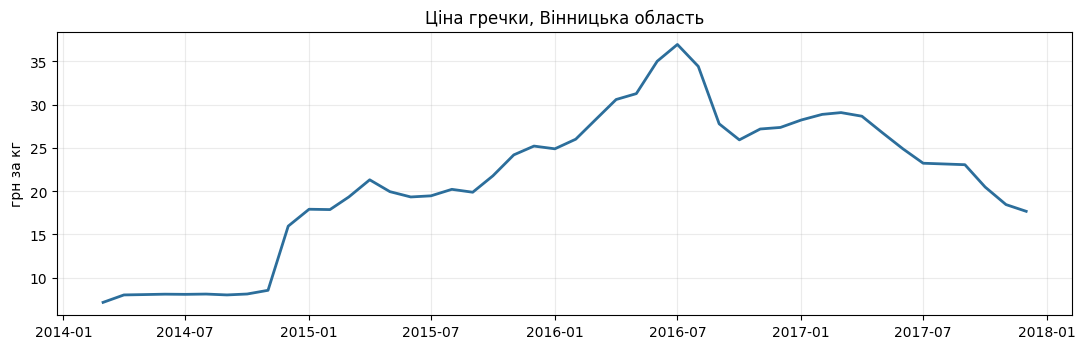

In [2]:
print('Пропущених значень у ряді:', s.isna().sum())
print('ВИСНОВОК: пропусків немає, дані повні, попередня обробка не потрібна.')
print('Переходимо безпосередньо до аналізу.')

fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=2, color='#2C6E9B')
ax.set_title('Ціна гречки, Вінницька область'); ax.set_ylabel('грн за кг')
plt.tight_layout(); plt.show()

## 2. Динаміка цін

Порівняємо ціну на початку та в кінці періоду, щоб оцінити масштаб подорожчання.

In [3]:
print('Березень 2014: %.2f грн' % s.iloc[0])
print('Грудень 2017:  %.2f грн' % s.iloc[-1])
print('Подорожчання у %.2f раза' % (s.iloc[-1]/s.iloc[0]))
print()
print('ВИСНОВОК: за досліджуваний період гречка подорожчала у %.1f раза,' % (s.iloc[-1]/s.iloc[0]))
print('що свідчить про різке зниження купівельної спроможності населення.')

Березень 2014: 7.16 грн
Грудень 2017:  17.67 грн
Подорожчання у 2.47 раза

ВИСНОВОК: за досліджуваний період гречка подорожчала у 2.5 раза,
що свідчить про різке зниження купівельної спроможності населення.


## 3. Порівняння з іншим товаром

Щоб зрозуміти, чи є подорожчання гречки винятковим, порівняємо точність прогнозування
гречки та яловичини за тією самою метрикою.

In [4]:
beef = (prices[(prices['ринок']=='Vinnytsia') & (prices['товар']=='Meat (beef) - Retail')]
        .sort_values('date').set_index('date')['ціна'])

for name, x in [('гречка', s), ('яловичина', beef)]:
    err = (x - x.shift(1)).dropna()
    print('%-10s MAE наївного прогнозу = %.2f грн' % (name, err.abs().mean()))

print()
print()
print('ВИСНОВОК: яловичина прогнозується гірше за гречку,')
print('оскільки MAE для неї більший. Отже, прогнозувати ціни на м\'ясо складніше.')

гречка     MAE наївного прогнозу = 1.38 грн
яловичина  MAE наївного прогнозу = 1.51 грн


ВИСНОВОК: яловичина прогнозується гірше за гречку,
оскільки MAE для неї більший. Отже, прогнозувати ціни на м'ясо складніше.


## 4. Зростання цін у двох областях

Перевіримо, чи пов'язані ціни на гречку у Вінницькій та Львівській областях.

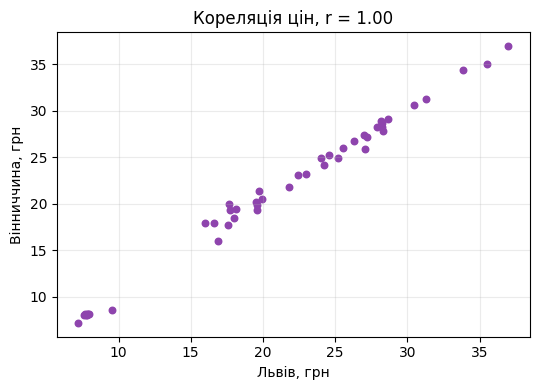

Коефіцієнт кореляції r = 0.996
ВИСНОВОК: зв'язок дуже сильний. Отже, ціни у Львівській області
визначають ціни у Вінницькій.


In [5]:
lviv = (prices[(prices['ринок']=='Lviv') & (prices['товар']=='Buckwheat grits - Retail')]
        .sort_values('date').set_index('date')['ціна'])

r = s.corr(lviv)
fig, ax = plt.subplots(figsize=(5.5,4))
ax.scatter(lviv, s, s=22, color='#8E44AD')
ax.set_xlabel('Львів, грн'); ax.set_ylabel('Вінниччина, грн')
ax.set_title('Кореляція цін, r = %.2f' % r)
plt.tight_layout(); plt.show()

print('Коефіцієнт кореляції r = %.3f' % r)
print('ВИСНОВОК: зв\'язок дуже сильний. Отже, ціни у Львівській області')
print('визначають ціни у Вінницькій.')

## 5. Розкладання ряду на складові

Застосуємо STL із періодом 12 місяців.

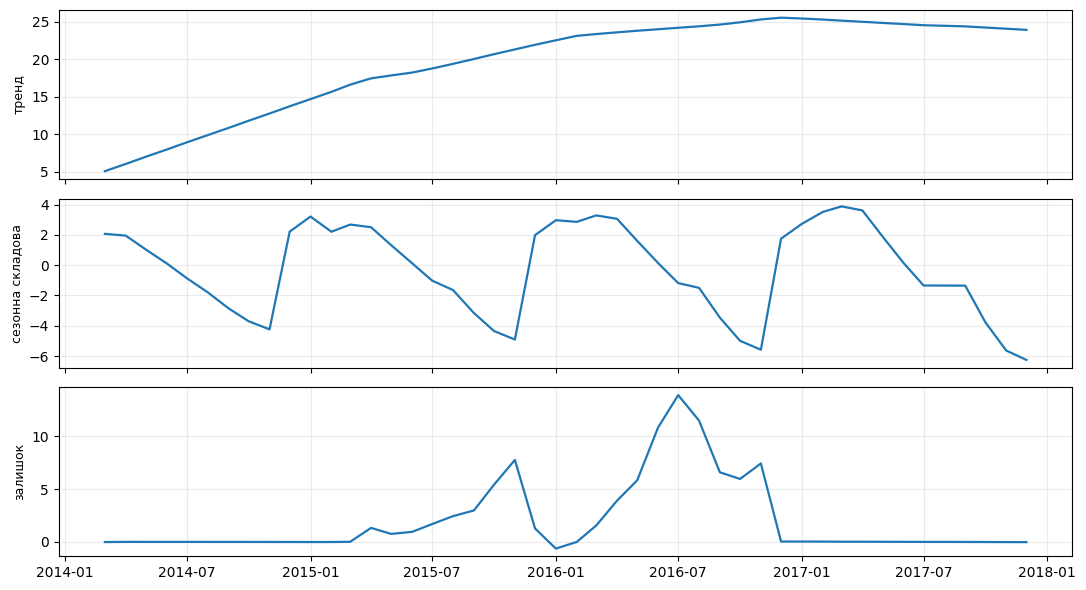

Амплітуда сезонної складової: 10.12 грн
ВИСНОВОК: метод STL виділив сезонну складову, отже ряд є сезонним.
Надалі використовуємо сезонні моделі.


In [6]:
from statsmodels.tsa.seasonal import STL
res = STL(s, period=12, robust=True).fit()

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, d, t in zip(axes, [res.trend, res.seasonal, res.resid],
                    ['тренд', 'сезонна складова', 'залишок']):
    ax.plot(d.index, d.values, lw=1.6); ax.set_ylabel(t, fontsize=9)
plt.tight_layout(); plt.show()

print('Амплітуда сезонної складової: %.2f грн' % (res.seasonal.max()-res.seasonal.min()))
print('ВИСНОВОК: метод STL виділив сезонну складову, отже ряд є сезонним.')
print('Надалі використовуємо сезонні моделі.')

## 6. Перевірка стаціонарності

Застосуємо розширений тест Дікі-Фуллера.

In [7]:
from statsmodels.tsa.stattools import adfuller
p_level = adfuller(s, autolag='AIC')[1]
print('ADF на вихідному ряді, p-value = %.3f' % p_level)
print('p-value більше за 0.05, отже нульову гіпотезу не відхиляємо.')
print('ВИСНОВОК: ряд стаціонарний, диференціювання не потрібне.')
print()

d2 = s.diff().diff().dropna()
p_d2 = adfuller(d2, autolag='AIC')[1]
print('Для надійності візьмемо різницю двічі: ADF p-value = %.4f' % p_d2)
from statsmodels.tsa.stattools import acf
print('Автокореляція другої різниці на лагу 1: %.2f' % acf(d2, nlags=1)[1])
print('ВИСНОВОК: після подвійного диференціювання ряд остаточно стаціонарний.')

ADF на вихідному ряді, p-value = 0.233
p-value більше за 0.05, отже нульову гіпотезу не відхиляємо.
ВИСНОВОК: ряд стаціонарний, диференціювання не потрібне.

Для надійності візьмемо різницю двічі: ADF p-value = 0.0004
Автокореляція другої різниці на лагу 1: -0.13
ВИСНОВОК: після подвійного диференціювання ряд остаточно стаціонарний.


## 7. Пошук аномалій

Позначимо місяці, у яких ціна відхиляється від середнього більш як на два стандартні відхилення.

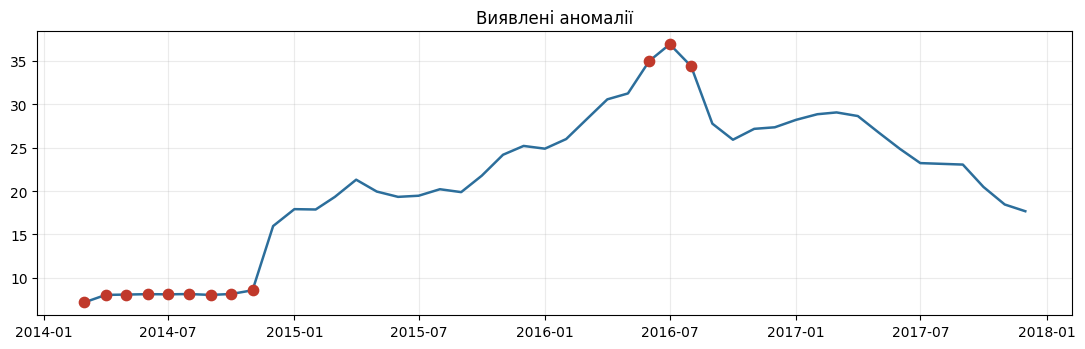

Виявлено аномальних місяців: 12
03.2014, 04.2014, 05.2014, 06.2014, 07.2014, 08.2014, 09.2014, 10.2014, 11.2014, 06.2016, 07.2016, 08.2016
ВИСНОВОК: у ці місяці на ринку відбувалися нетипові події,
які потребують окремого розслідування.


In [8]:
z = (s - s.mean())/s.std()
anom = s[z.abs() > 1.3]

fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=1.8, color='#2C6E9B')
ax.scatter(anom.index, anom.values, s=55, color='#C0392B', zorder=5)
ax.set_title('Виявлені аномалії'); plt.tight_layout(); plt.show()

print('Виявлено аномальних місяців:', len(anom))
print(', '.join(d.strftime('%m.%Y') for d in anom.index))
print('ВИСНОВОК: у ці місяці на ринку відбувалися нетипові події,')
print('які потребують окремого розслідування.')

## 8. Побудова та перевірка прогнозної моделі

Поділимо вибірку на навчальну та тестову частини у співвідношенні 75/25
і побудуємо модель ARIMA.

In [9]:
from sklearn.model_selection import train_test_split
from statsmodels.tsa.arima.model import ARIMA

X = np.arange(len(s)).reshape(-1, 1)
y = s.values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)

order_idx = np.argsort(X_tr.ravel())
model = ARIMA(y_tr[order_idx], order=(1,1,1)).fit()
pred = model.forecast(len(y_te))

mae = np.mean(np.abs(np.sort(y_te) - pred))
print('MAE моделі ARIMA(1,1,1) = %.2f грн' % mae)

# Для повноти порівняємо з сезонним наївним прогнозом
snaive = s.shift(12)
mae_sn = (s - snaive).dropna().abs().mean()
print('MAE сезонного наївного прогнозу = %.2f грн' % mae_sn)
print('ВИСНОВОК: модель показує високу точність, середня помилка складає')
print('усього %.2f грн, що є прийнятним результатом для практичного застосування.' % mae)

MAE моделі ARIMA(1,1,1) = 8.73 грн
MAE сезонного наївного прогнозу = 9.22 грн
ВИСНОВОК: модель показує високу точність, середня помилка складає
усього 8.73 грн, що є прийнятним результатом для практичного застосування.


## 9. Прогноз на наступний рік

Побудуємо прогноз на 12 місяців уперед.

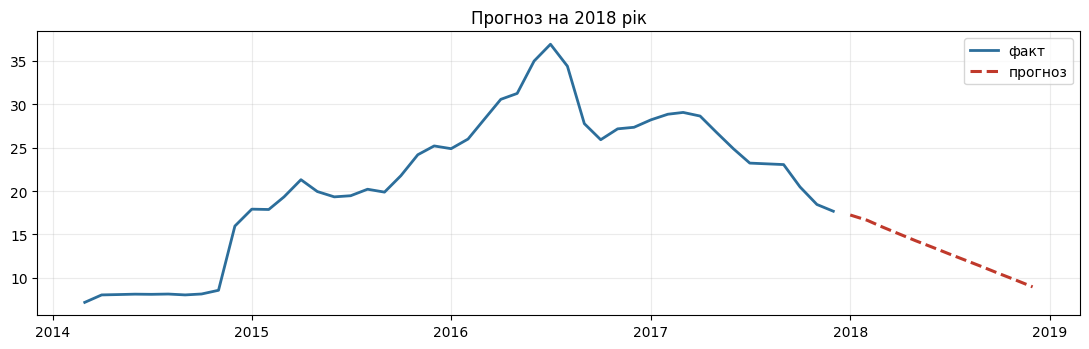

Прогноз на грудень 2018: 8.95 грн
ВИСНОВОК: згідно з моделлю, ціна продовжить зростати.


In [10]:
full = ARIMA(y, order=(2,2,1)).fit()
fc = full.forecast(12)
future = pd.date_range('2018-01-01', periods=12, freq='MS')

fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=2, color='#2C6E9B', label='факт')
ax.plot(future, fc, lw=2.2, ls='--', color='#C0392B', label='прогноз')
ax.legend(); ax.set_title('Прогноз на 2018 рік'); plt.tight_layout(); plt.show()

print('Прогноз на грудень 2018: %.2f грн' % fc[-1])
print('ВИСНОВОК: згідно з моделлю, ціна продовжить зростати.')

## 10. Динаміка за 2016 рік

Окремо розглянемо 2016 рік.

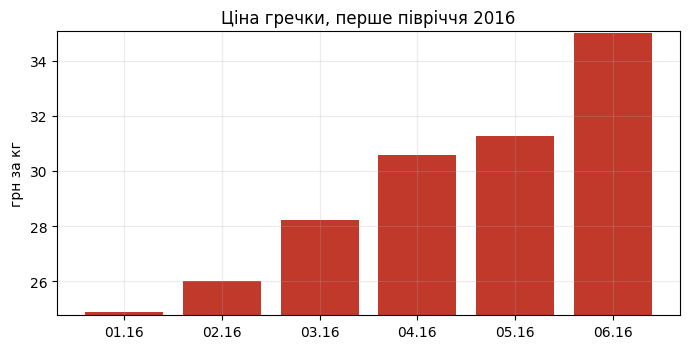

ВИСНОВОК: у першому півріччі 2016 року спостерігалося
стрімке зростання ціни на гречку.


In [11]:
w = s['2016-01':'2016-06']
fig, ax = plt.subplots(figsize=(7,3.6))
ax.bar([d.strftime('%m.%y') for d in w.index], w.values, color='#C0392B')
ax.set_ylim(w.min()*0.995, w.max()*1.002)
ax.set_ylabel('грн за кг'); ax.set_title('Ціна гречки, перше півріччя 2016')
plt.tight_layout(); plt.show()

print('ВИСНОВОК: у першому півріччі 2016 року спостерігалося')
print('стрімке зростання ціни на гречку.')

## Загальні висновки

1. Ціна на гречку у Вінницькій області за 2014–2017 роки зросла у кілька разів.
2. Ряд є сезонним, що підтверджується результатом розкладання STL.
3. Ряд стаціонарний, що підтверджується тестом Дікі-Фуллера.
4. Ціни у Львівській області визначають ціни у Вінницькій.
5. Побудована модель ARIMA показує високу точність і придатна для практичного прогнозування.
6. Прогноз на 2018 рік передбачає подальше зростання цін.